In [1]:
from sklearn.pipeline import Pipeline

In [2]:
from google.colab import drive

drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [3]:
import os

project_path = "/content/drive/MyDrive/ML_Assignment"

print("Folder exists:", os.path.exists(project_path))

if os.path.exists(project_path):
    print(os.listdir(project_path))

Folder exists: True
['Notebooks', 'Data', 'Results', '.ipynb_checkpoints', 'Price Predictor Demo video.mp4']


In [4]:
import glob

csv_files = glob.glob(
    project_path + "/**/*.csv",
    recursive=True
)

for file in csv_files:
    print(file)

/content/drive/MyDrive/ML_Assignment/Notebooks/ML_Assignment/Notebooks/ML_Assignment/Notebooks/ML_Assignment/Notebooks/ML_Assignment/Notebooks/ML_Assignment/Notebooks/ML_Assignment/Notebooks/ML_Assignment/Notebooks/ML_Assignment/Notebooks/ML_Assignment/Notebooks/ML_Assignment/Notebooks/ML_Assignment/Notebooks/ML_Assignment/Notebooks/ML_Assignment/Notebooks/ML_Assignment/Notebooks/ML_Assignment/Notebooks/ML_Assignment/Notebooks/ML_Assignment/Notebooks/ML_Assignment/Notebooks/ML_Assignment/Notebooks/ML_Assignment/Notebooks/ML_Assignment/Notebooks/ML_Assignment/Notebooks/ML_Assignment/Notebooks/ML_Assignment/Notebooks/ML_Assignment/Notebooks/ML_Assignment/Notebooks/ML_Assignment/Notebooks/ML_Assignment/Notebooks/ML_Assignment/Notebooks/ML_Assignment/Notebooks/ML_Assignment/Notebooks/ML_Assignment/Notebooks/ML_Assignment/Notebooks/ML_Assignment/Notebooks/ML_Assignment/Notebooks/ML_Assignment/Notebooks/ML_Assignment/Notebooks/ML_Assignment/Notebooks/ML_Assignment/Data/test.csv
/content/driv

In [5]:
# ============================================================
# LOAD THE FINAL PREPROCESSED TRAINING DATASET
# ============================================================

import pandas as pd
import numpy as np

train_path = (
    "/content/drive/MyDrive/ML_Assignment/"
    "Results/Outputs/final_preprocessed_train.csv"
)

# Preserve "None" as a meaningful category
train_df = pd.read_csv(
    train_path,
    keep_default_na=False,
    na_values=[""]
)

# Separate input features and target
X = train_df.drop(columns=["SalePrice"])
y = train_df["SalePrice"]

# Log-transform the target
y_log = np.log1p(y)

print("Training features:", X.shape)
print("Target:", y.shape)

display(train_df.head())

Training features: (1460, 75)
Target: (1460,)


,OverallQual,TotalSF,GrLivArea,GarageCars,TotalBathrooms,GarageArea,TotalBsmtSF,1stFlrSF,FullBath,TotRmsAbvGrd,...,Condition1,Alley,ExterCond,PoolQC,LotConfig,Functional,Heating,MiscFeature,Condition2,SalePrice
0,7,2566,1710,2,3.5,548,856,856,2,8,...,Norm,None,TA,None,Inside,Typ,GasA,None,Norm,208500
1,6,2524,1262,2,2.5,460,1262,1262,2,6,...,Feedr,None,TA,None,FR2,Typ,GasA,None,Norm,181500
2,7,2706,1786,2,3.5,608,920,920,2,6,...,Norm,None,TA,None,Inside,Typ,GasA,None,Norm,223500
3,7,2473,1717,3,2.0,642,756,961,1,7,...,Norm,None,TA,None,Corner,Typ,GasA,None,Norm,140000
4,8,3343,2198,3,3.5,836,1145,1145,2,9,...,Norm,None,TA,None,FR2,Typ,GasA,None,Norm,250000


In [6]:
# ============================================================
# SECTION 1: IMPORT LIBRARIES
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.model_selection import (
    KFold,
    cross_validate,
    cross_val_predict
)

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

from xgboost import XGBRegressor

print("All libraries imported successfully!")

All libraries imported successfully!


In [7]:
# ============================================================
# SECTION 2: IDENTIFY FEATURE TYPES
# ============================================================

# Correct categorical codes after loading CSV
for col in ["MSSubClass", "MoSold"]:
    if col in X.columns:
        X[col] = X[col].astype(str)

# Numerical features
numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

# Categorical features
categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

print("Total features:",
      len(numeric_features) + len(categorical_features))

Numerical features: 34
Categorical features: 41
Total features: 75


In [8]:
# ============================================================
# SECTION 3: PREPROCESSING PIPELINE
# ============================================================

# Numerical preprocessing:
# 1. Fill missing numerical values using the median
# 2. Standardize numerical values

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])


# Categorical preprocessing:
# 1. Fill missing categorical values using the mode
# 2. Convert categorical features using One-Hot Encoding

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])


# Combine numerical and categorical transformations

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [9]:
# ============================================================
# SECTION 4: CREATE XGBOOST REGRESSION MODEL
# ============================================================

xgb_pipeline = Pipeline([
    ("preprocessor", preprocessor),

    ("model", XGBRegressor(
        n_estimators=500,
        learning_rate=0.05,
        max_depth=3,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        tree_method="hist",
        random_state=42,
        n_jobs=-1
    ))
])

print("XGBoost pipeline created successfully!")

XGBoost pipeline created successfully!


In [10]:
# ============================================================
# SECTION 5: DEFINE 5-FOLD CROSS-VALIDATION
# ============================================================

kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluation metrics
scoring = {
    "rmse": "neg_root_mean_squared_error",
    "mae": "neg_mean_absolute_error",
    "r2": "r2"
}

print("5-Fold Cross-Validation configured!")

5-Fold Cross-Validation configured!


In [11]:
# ============================================================
# SECTION 6: TRAIN AND EVALUATE USING 5-FOLD CV
# ============================================================

xgb_cv = cross_validate(
    xgb_pipeline,
    X,
    y_log,
    cv=kf,
    scoring=scoring,
    return_train_score=True,
    n_jobs=1,
    error_score="raise"
)

print("XGBoost 5-Fold Cross-Validation completed!")

XGBoost 5-Fold Cross-Validation completed!


In [12]:
# ============================================================
# SECTION 7: CREATE CROSS-VALIDATION RESULTS TABLE
# ============================================================

xgb_results = pd.DataFrame({
    "Fold": range(1, 6),

    "Train_RMSE": -xgb_cv["train_rmse"],
    "Validation_RMSE": -xgb_cv["test_rmse"],

    "Train_MAE": -xgb_cv["train_mae"],
    "Validation_MAE": -xgb_cv["test_mae"],

    "Train_R2": xgb_cv["train_r2"],
    "Validation_R2": xgb_cv["test_r2"]
})

display(xgb_results.round(4))

,Fold,Train_RMSE,Validation_RMSE,Train_MAE,Validation_MAE,Train_R2,Validation_R2
0,1,0.0570,0.1323,0.0426,0.0887,0.9787,0.9062
1,2,0.0571,0.1166,0.0429,0.0821,0.9797,0.9125
2,3,0.0564,0.1653,0.0424,0.0930,0.9806,0.8060
3,4,0.0583,0.1190,0.0434,0.0832,0.9780,0.9200
4,5,0.0570,0.1174,0.0432,0.0771,0.9804,0.8985


In [13]:
# ============================================================
# SECTION 8: SUMMARIZE XGBOOST MODEL PERFORMANCE
# ============================================================

print("XGBOOST - 5 FOLD CROSS-VALIDATION")
print("------------------------------------------")

print("Mean Validation RMSE:",
      xgb_results["Validation_RMSE"].mean())

print("Mean Validation MAE:",
      xgb_results["Validation_MAE"].mean())

print("Mean Validation R²:",
      xgb_results["Validation_R2"].mean())

print("------------------------------------------")

print("RMSE Standard Deviation:",
      xgb_results["Validation_RMSE"].std())

print("MAE Standard Deviation:",
      xgb_results["Validation_MAE"].std())

print("R² Standard Deviation:",
      xgb_results["Validation_R2"].std())

XGBOOST - 5 FOLD CROSS-VALIDATION
------------------------------------------
Mean Validation RMSE: 0.13011876866440844
Mean Validation MAE: 0.08481790106093434
Mean Validation R²: 0.8886167504750414
------------------------------------------
RMSE Standard Deviation: 0.020684719479437303
MAE Standard Deviation: 0.00613245485260975
R² Standard Deviation: 0.0468565707079659


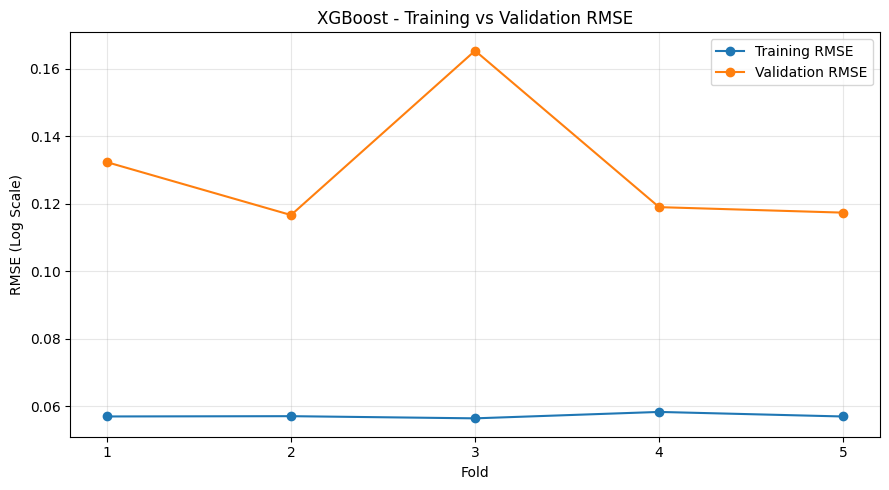

In [14]:
# ============================================================
# SECTION 9: TRAINING VS VALIDATION RMSE
# ============================================================

plt.figure(figsize=(9, 5))

plt.plot(
    xgb_results["Fold"],
    xgb_results["Train_RMSE"],
    marker="o",
    label="Training RMSE"
)

plt.plot(
    xgb_results["Fold"],
    xgb_results["Validation_RMSE"],
    marker="o",
    label="Validation RMSE"
)

plt.xlabel("Fold")
plt.ylabel("RMSE (Log Scale)")
plt.title("XGBoost - Training vs Validation RMSE")

plt.xticks(range(1, 6))
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [15]:
# ============================================================
# SECTION 10: GENERATE OUT-OF-FOLD PREDICTIONS
# ============================================================

xgb_pred = cross_val_predict(
    xgb_pipeline,
    X,
    y_log,
    cv=kf,
    n_jobs=1
)

print("Predictions generated:", len(xgb_pred))

Predictions generated: 1460


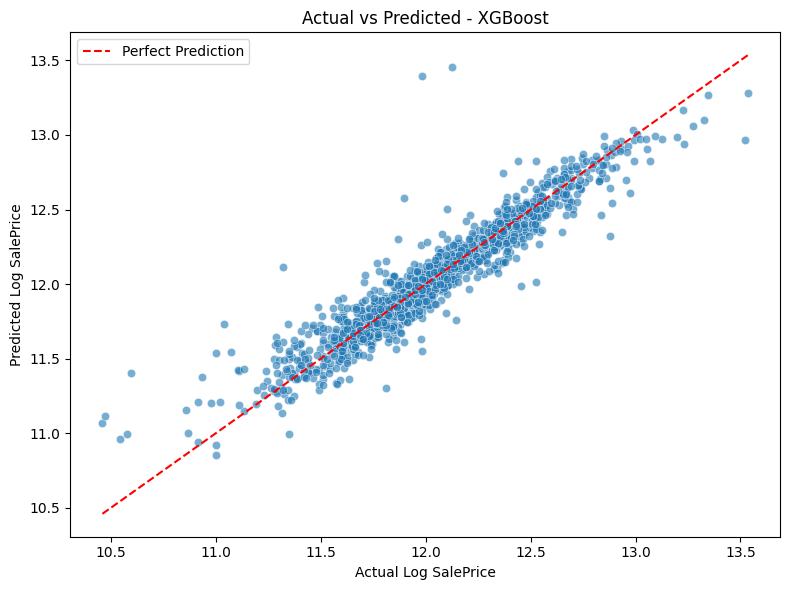

In [16]:
# ============================================================
# SECTION 11: ACTUAL VS PREDICTED VISUALIZATION
# ============================================================

plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=y_log,
    y=xgb_pred,
    alpha=0.6
)

min_value = min(y_log.min(), xgb_pred.min())
max_value = max(y_log.max(), xgb_pred.max())

# Perfect prediction reference line
plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--",
    color="red",
    label="Perfect Prediction"
)

plt.xlabel("Actual Log SalePrice")
plt.ylabel("Predicted Log SalePrice")
plt.title("Actual vs Predicted - XGBoost")

plt.legend()
plt.tight_layout()
plt.show()

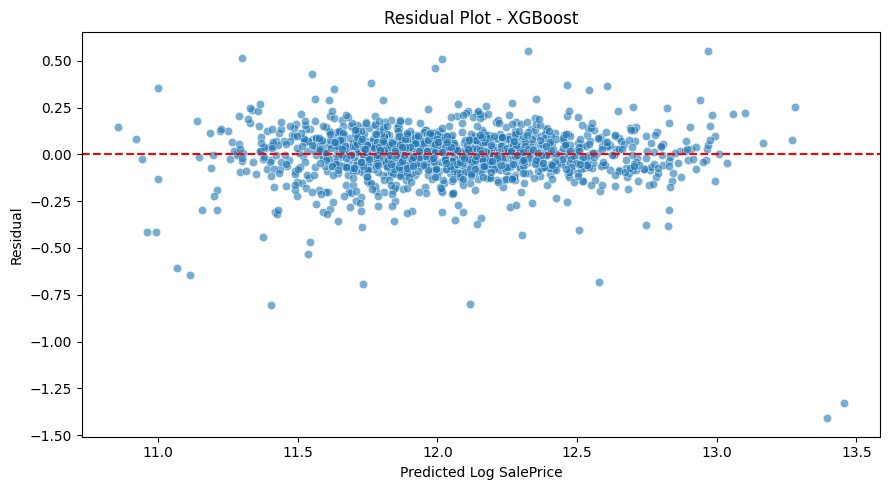

In [17]:
# ============================================================
# SECTION 12: RESIDUAL ANALYSIS
# ============================================================

# Residual = Actual - Predicted
xgb_residuals = y_log - xgb_pred

plt.figure(figsize=(9, 5))

sns.scatterplot(
    x=xgb_pred,
    y=xgb_residuals,
    alpha=0.6
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--"
)

plt.xlabel("Predicted Log SalePrice")
plt.ylabel("Residual")
plt.title("Residual Plot - XGBoost")

plt.tight_layout()
plt.show()

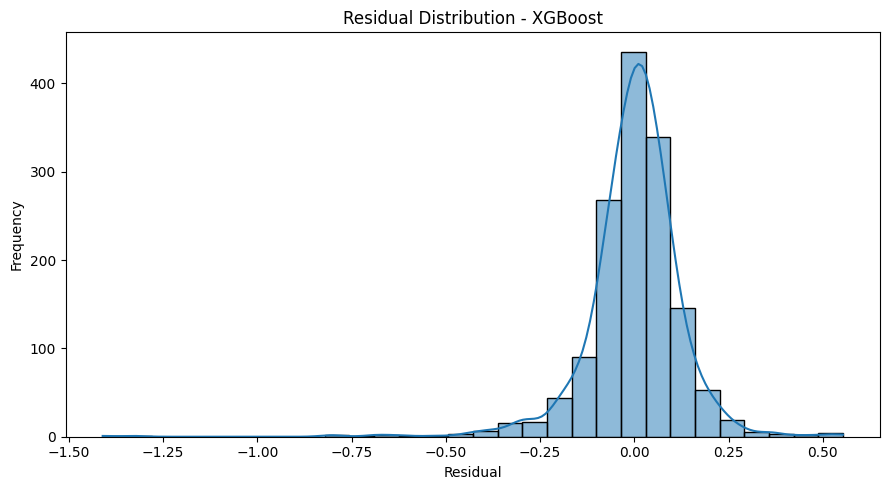

In [18]:
# ============================================================
# SECTION 13: RESIDUAL DISTRIBUTION
# ============================================================

plt.figure(figsize=(9, 5))

sns.histplot(
    xgb_residuals,
    bins=30,
    kde=True
)

plt.xlabel("Residual")
plt.ylabel("Frequency")
plt.title("Residual Distribution - XGBoost")

plt.tight_layout()
plt.show()

In [19]:
# ============================================================
# SECTION 14: OVERALL OUT-OF-FOLD METRICS
# ============================================================

overall_rmse = np.sqrt(
    mean_squared_error(y_log, xgb_pred)
)

overall_mae = mean_absolute_error(
    y_log,
    xgb_pred
)

overall_r2 = r2_score(
    y_log,
    xgb_pred
)

print("XGBOOST - OVERALL OUT-OF-FOLD PERFORMANCE")
print("------------------------------------------")
print("RMSE:", overall_rmse)
print("MAE:", overall_mae)
print("R²:", overall_r2)

XGBOOST - OVERALL OUT-OF-FOLD PERFORMANCE
------------------------------------------
RMSE: 0.1314274707003686
MAE: 0.08481790106093436
R²: 0.8916705362933424


In [20]:
# ============================================================
# SECTION 15: FIT XGBOOST FOR FEATURE IMPORTANCE
# ============================================================

xgb_pipeline.fit(X, y_log)

print("XGBoost model fitted successfully!")

XGBoost model fitted successfully!


In [21]:
# ============================================================
# SECTION 16: EXTRACT FEATURE IMPORTANCE
# ============================================================

# Obtain feature names after One-Hot Encoding
feature_names = (
    xgb_pipeline
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

# Obtain feature importance scores
importances = (
    xgb_pipeline
    .named_steps["model"]
    .feature_importances_
)

# Create importance table
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

display(importance_df.head(20))

,Feature,Importance
0,num__OverallQual,0.113571
62,cat__ExterQual_TA,0.107233
1,num__TotalSF,0.071092
207,cat__CentralAir_Y,0.053247
63,cat__BsmtQual_Ex,0.037062
71,cat__KitchenQual_TA,0.036722
16,num__HasFireplace,0.032126
206,cat__CentralAir_N,0.026127
181,cat__MSZoning_RM,0.026103
4,num__TotalBathrooms,0.024940


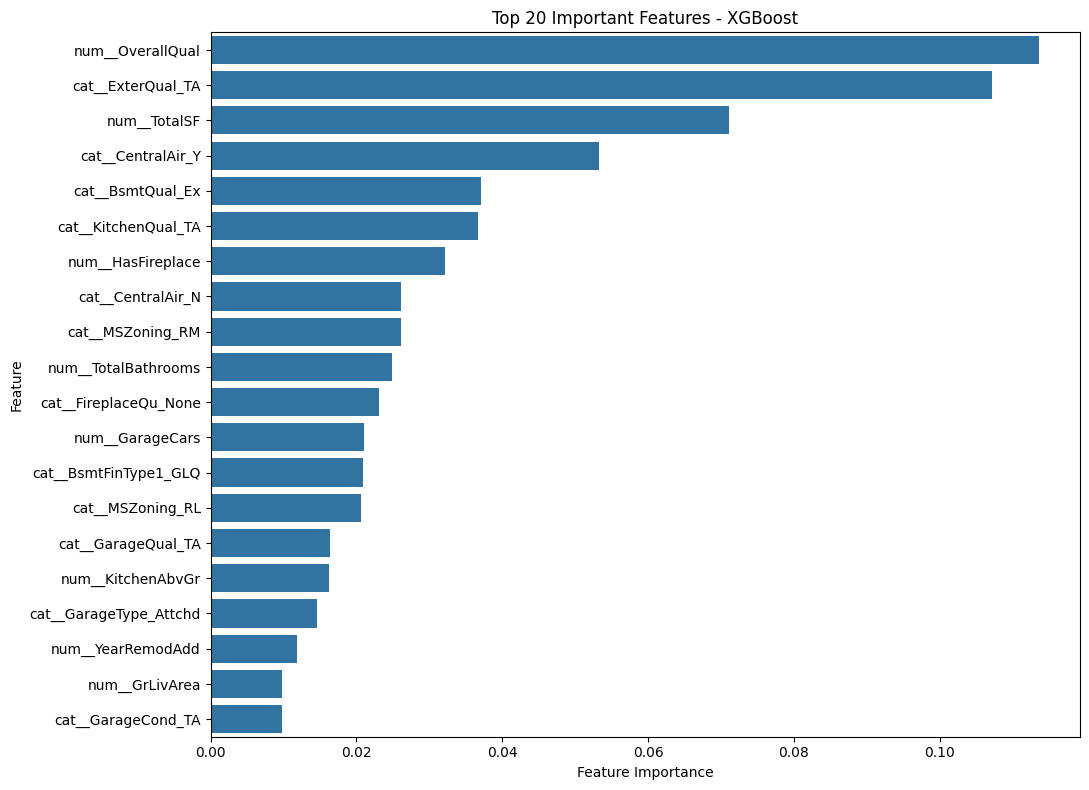

In [22]:
# ============================================================
# SECTION 17: TOP 20 FEATURE IMPORTANCE VISUALIZATION
# ============================================================

top_20 = importance_df.head(20)

plt.figure(figsize=(11, 8))

sns.barplot(
    data=top_20,
    x="Importance",
    y="Feature"
)

plt.title("Top 20 Important Features - XGBoost")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [23]:
# ============================================================
# SECTION 18: SAVE XGBOOST RESULTS
# ============================================================

import os

output_path = (
    "/content/drive/MyDrive/ML_Assignment/"
    "Results/Outputs/"
)

os.makedirs(output_path, exist_ok=True)

# Save fold-wise cross-validation results
xgb_results.to_csv(
    output_path + "xgboost_results.csv",
    index=False
)

# Save feature importance table
importance_df.to_csv(
    output_path + "xgboost_feature_importance.csv",
    index=False
)

print("XGBoost results saved successfully!")

XGBoost results saved successfully!


# Hyperparameter Tuning - XGBoost

In [24]:
# ============================================================
# SECTION 19: IMPORT HYPERPARAMETER TUNING LIBRARIES
# ============================================================

from sklearn.model_selection import RandomizedSearchCV

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [25]:
# ============================================================
# SECTION 20: DEFINE HYPERPARAMETER SEARCH SPACE
# ============================================================

param_grid = {

    # Number of boosting trees
    "model__n_estimators": [200, 300, 500],

    # Maximum tree depth
    "model__max_depth": [2, 3, 4],

    # Learning rate
    "model__learning_rate": [0.03, 0.05, 0.1],

    # Fraction of observations used for each tree
    "model__subsample": [0.8, 1.0],

    # Fraction of features used for each tree
    "model__colsample_bytree": [0.8, 1.0],

    # Minimum child weight
    "model__min_child_weight": [1, 3, 5]
}

print("Hyperparameter search space defined!")

Hyperparameter search space defined!


In [26]:
# ============================================================
# SECTION 21: XGBOOST HYPERPARAMETER TUNING
# ============================================================

random_search = RandomizedSearchCV(

    # Existing XGBoost pipeline
    estimator=xgb_pipeline,

    # Hyperparameter combinations
    param_distributions=param_grid,

    # Number of combinations to test
    n_iter=12,

    # Evaluation metric
    scoring="neg_root_mean_squared_error",

    # 5-Fold Cross-Validation
    cv=kf,

    # Reproducibility
    random_state=42,

    # Number of parallel CV jobs
    n_jobs=1,

    # Display training progress
    verbose=1,

    # Refit best model on the available data
    refit=True,

    # Show the actual error if fitting fails
    error_score="raise"
)

# Perform hyperparameter search
random_search.fit(X, y_log)

print("Hyperparameter tuning completed successfully!")

Fitting 5 folds for each of 12 candidates, totalling 60 fits
Hyperparameter tuning completed successfully!


In [27]:
# ============================================================
# SECTION 22: DISPLAY BEST HYPERPARAMETERS
# ============================================================

print("BEST XGBOOST HYPERPARAMETERS")
print("------------------------------------")

for parameter, value in random_search.best_params_.items():
    print(parameter, ":", value)

print("------------------------------------")

print(
    "Best CV RMSE:",
    round(-random_search.best_score_, 4)
)

BEST XGBOOST HYPERPARAMETERS
------------------------------------
model__subsample : 0.8
model__n_estimators : 200
model__min_child_weight : 1
model__max_depth : 4
model__learning_rate : 0.1
model__colsample_bytree : 0.8
------------------------------------
Best CV RMSE: 0.1308


In [28]:
# ============================================================
# SECTION 23: CREATE TUNING RESULTS TABLE
# ============================================================

tuning_results = pd.DataFrame(
    random_search.cv_results_
)

# Convert negative RMSE to positive
tuning_results["Mean_RMSE"] = (
    -tuning_results["mean_test_score"]
)

tuning_results["RMSE_SD"] = (
    tuning_results["std_test_score"]
)

# Sort by best RMSE
tuning_results = tuning_results.sort_values(
    by="Mean_RMSE",
    ascending=True
)

# Display useful columns
display(
    tuning_results[
        [
            "params",
            "Mean_RMSE",
            "RMSE_SD",
            "rank_test_score"
        ]
    ].head(12)
)

,params,Mean_RMSE,RMSE_SD,rank_test_score
9,"{'model__subsample': 0.8, 'model__n_estimators...",0.130849,0.016921,1
5,"{'model__subsample': 0.8, 'model__n_estimators...",0.131069,0.017837,2
0,"{'model__subsample': 0.8, 'model__n_estimators...",0.132251,0.018466,3
7,"{'model__subsample': 0.8, 'model__n_estimators...",0.133438,0.018329,4
1,"{'model__subsample': 0.8, 'model__n_estimators...",0.133444,0.018707,5
8,"{'model__subsample': 0.8, 'model__n_estimators...",0.133774,0.018429,6
2,"{'model__subsample': 1.0, 'model__n_estimators...",0.134081,0.017514,7
10,"{'model__subsample': 1.0, 'model__n_estimators...",0.135895,0.016400,8
4,"{'model__subsample': 0.8, 'model__n_estimators...",0.136873,0.016086,9
6,"{'model__subsample': 1.0, 'model__n_estimators...",0.137134,0.017123,10


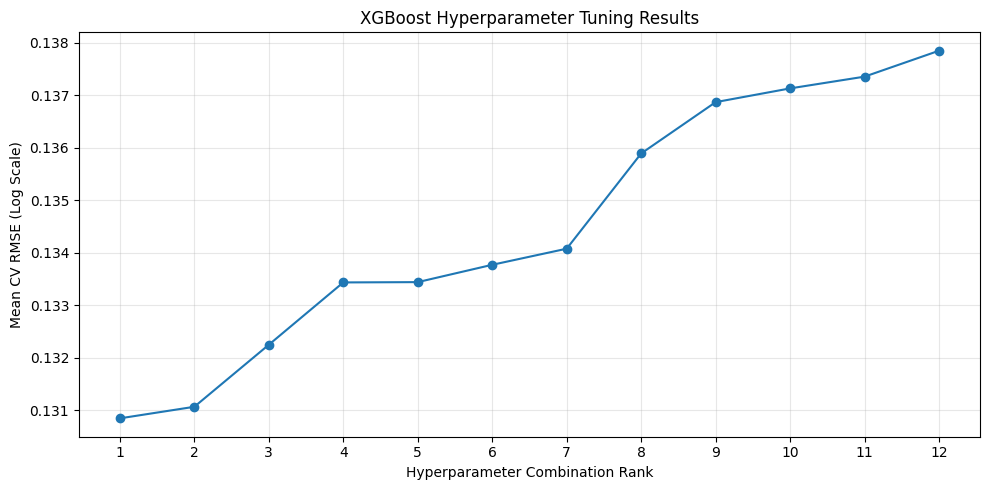

In [29]:
# ============================================================
# SECTION 24: VISUALIZE HYPERPARAMETER TUNING RESULTS
# ============================================================

plot_results = tuning_results.sort_values(
    "rank_test_score"
).reset_index(drop=True)

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(plot_results) + 1),
    plot_results["Mean_RMSE"],
    marker="o"
)

plt.xlabel("Hyperparameter Combination Rank")
plt.ylabel("Mean CV RMSE (Log Scale)")
plt.title("XGBoost Hyperparameter Tuning Results")

plt.xticks(range(1, len(plot_results) + 1))
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [30]:
# ============================================================
# SECTION 25: INITIAL VS TUNED XGBOOST
# ============================================================

initial_rmse = xgb_results["Validation_RMSE"].mean()

tuned_rmse = -random_search.best_score_

tuning_comparison = pd.DataFrame({

    "Model": [
        "Initial XGBoost",
        "Tuned XGBoost"
    ],

    "CV_RMSE": [
        initial_rmse,
        tuned_rmse
    ]
})

display(tuning_comparison.round(4))

,Model,CV_RMSE
0,Initial XGBoost,0.1301
1,Tuned XGBoost,0.1308


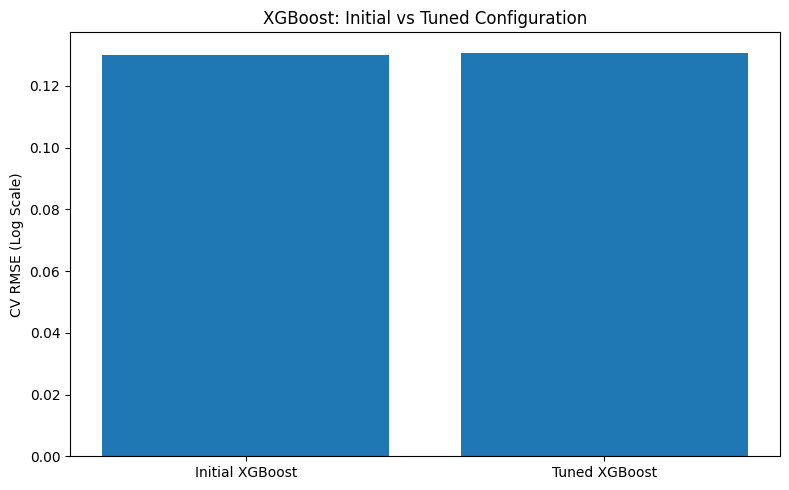

In [31]:
# ============================================================
# SECTION 26: COMPARE RMSE BEFORE AND AFTER TUNING
# ============================================================

plt.figure(figsize=(8, 5))

plt.bar(
    tuning_comparison["Model"],
    tuning_comparison["CV_RMSE"]
)

plt.ylabel("CV RMSE (Log Scale)")
plt.title("XGBoost: Initial vs Tuned Configuration")

plt.tight_layout()
plt.show()

In [32]:
# ============================================================
# SECTION 27: SAVE HYPERPARAMETER TUNING RESULTS
# ============================================================

import os

output_path = (
    "/content/drive/MyDrive/ML_Assignment/"
    "Results/Outputs/"
)

os.makedirs(output_path, exist_ok=True)

# Save all tuning combinations
tuning_results.to_csv(
    output_path + "xgboost_tuning_results.csv",
    index=False
)

# Save preliminary comparison
tuning_comparison.to_csv(
    output_path + "xgboost_tuning_comparison.csv",
    index=False
)

print("Hyperparameter tuning results saved successfully!")

Hyperparameter tuning results saved successfully!


In [33]:
# ============================================================
# SECTION 28: SELECT PREFERRED XGBOOST CONFIGURATION
# ============================================================

initial_rmse = xgb_results["Validation_RMSE"].mean()
tuned_rmse = -random_search.best_score_

print("Initial XGBoost RMSE:", round(initial_rmse, 4))
print("Tuned XGBoost RMSE:", round(tuned_rmse, 4))

if initial_rmse <= tuned_rmse:
    print("\nPreferred configuration: Initial XGBoost")
    print("Reason: Lower cross-validation RMSE.")
else:
    print("\nTuned configuration is promising.")
    print("Further independent validation is recommended.")

Initial XGBoost RMSE: 0.1301
Tuned XGBoost RMSE: 0.1308

Preferred configuration: Initial XGBoost
Reason: Lower cross-validation RMSE.


In [34]:
xgb_results.to_csv(
    output_path + "xgboost_results.csv",
    index=False
)

print("Updated XGBoost results saved!")

Updated XGBoost results saved!


In [35]:
# ============================================================
# SECTION 1: LOAD MODEL RESULTS
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import os

# Correct Google Drive folder path
base_path = "/content/drive/MyDrive/ML_Assignment/Results/Outputs/"

# Load initial XGBoost results
xgb_results = pd.read_csv(
    base_path + "xgboost_results.csv"
)

# Load Gradient Boosting tuning results
gb_tuning = pd.read_csv(
    base_path + "gradient_boosting_tuning_comparison.csv"
)

print("Model results loaded successfully!")

Model results loaded successfully!


In [36]:
# ============================================================
# SECTION 2: COMPARE XGBOOST AND TUNED GRADIENT BOOSTING
# ============================================================

# Initial XGBoost mean RMSE
xgb_initial_rmse = xgb_results["Validation_RMSE"].mean()

# Tuned Gradient Boosting RMSE
gb_tuned_rmse = gb_tuning.loc[
    gb_tuning["Model"] == "Tuned Gradient Boosting",
    "CV_RMSE"
].iloc[0]

# Create comparison table
comparison = pd.DataFrame({
    "Model": [
        "Initial XGBoost",
        "Tuned Gradient Boosting"
    ],

    "CV_RMSE": [
        xgb_initial_rmse,
        gb_tuned_rmse
    ]
})

# Sort by lowest RMSE
comparison = comparison.sort_values(
    by="CV_RMSE",
    ascending=True
).reset_index(drop=True)

display(comparison.round(4))

,Model,CV_RMSE
0,Initial XGBoost,0.1301
1,Tuned Gradient Boosting,0.1306


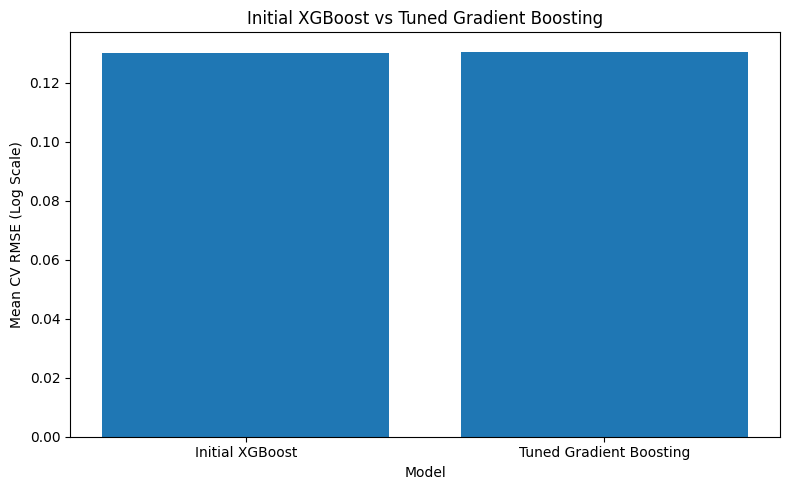

In [37]:
# ============================================================
# SECTION 3: VISUALIZE MODEL COMPARISON
# ============================================================

plt.figure(figsize=(8, 5))

plt.bar(
    comparison["Model"],
    comparison["CV_RMSE"]
)

plt.xlabel("Model")
plt.ylabel("Mean CV RMSE (Log Scale)")
plt.title("Initial XGBoost vs Tuned Gradient Boosting")

plt.tight_layout()
plt.show()

In [38]:
# ============================================================
# SECTION 4: IDENTIFY PREFERRED MODEL
# ============================================================

best_model = comparison.iloc[0]

print("MODEL COMPARISON RESULTS")
print("--------------------------------")

print("Model with lowest CV RMSE:", best_model["Model"])
print("Mean CV RMSE:", round(best_model["CV_RMSE"], 4))

MODEL COMPARISON RESULTS
--------------------------------
Model with lowest CV RMSE: Initial XGBoost
Mean CV RMSE: 0.1301


In [39]:
# ============================================================
# SECTION 5: SAVE COMPARISON RESULTS
# ============================================================

comparison.to_csv(
    base_path + "final_candidate_comparison.csv",
    index=False
)

print("Comparison results saved successfully!")

Comparison results saved successfully!


Create The Demo


In [40]:
# ============================================================
# FINAL OPTIONAL STEP: EXPORT XGBOOST PIPELINE FOR A DEMO
# Run the dataset, preprocessing, and model-definition cells first.
# ============================================================

from pathlib import Path
import json
import joblib

# This explicit check gives a useful message if you run this cell by itself.
if "xgb_pipeline" not in globals():
    raise RuntimeError(
        "XGBoost pipeline is not defined. Run the notebook from the top "
        "through 'SECTION 4: CREATE XGBOOST REGRESSION MODEL' first."
    )

# Fit one final copy on the available labelled training data for demo use.
# These are not held-out evaluation predictions.
xgb_pipeline.fit(X, y_log)

export_dir = Path("/content/drive/MyDrive/ML_Assignment/Results/Outputs")
export_dir.mkdir(parents=True, exist_ok=True)

model_file = export_dir / "xgb_housing_pipeline.joblib"
columns_file = export_dir / "feature_columns.joblib"
schema_file = export_dir / "feature_schema.json"
sample_file = export_dir / "sample_input.csv"

joblib.dump(xgb_pipeline, model_file)
joblib.dump(X.columns.tolist(), columns_file)
with open(schema_file, "w", encoding="utf-8") as f:
    json.dump(X.columns.tolist(), f, indent=2)
X.head(5).to_csv(sample_file, index=False)

print("XGBoost demo files saved to Google Drive:")
for path in [model_file, columns_file, schema_file, sample_file]:
    print(" -", path)
print("Note: Final report model selection is based on separate nested CV.")


XGBoost demo files saved to Google Drive:
 - /content/drive/MyDrive/ML_Assignment/Results/Outputs/xgb_housing_pipeline.joblib
 - /content/drive/MyDrive/ML_Assignment/Results/Outputs/feature_columns.joblib
 - /content/drive/MyDrive/ML_Assignment/Results/Outputs/feature_schema.json
 - /content/drive/MyDrive/ML_Assignment/Results/Outputs/sample_input.csv
Note: Final report model selection is based on separate nested CV.
